# FinQA preprocessing analysis

This M2 notebook turns the existing EDA and anomaly investigation into conservative preprocessing decisions. It does not train a model, alter the official splits, or write to the raw dataset.

The official FinQA repository records that an earlier `table_row_to_text` bug leaked label information and inflated retriever scores. Therefore, every representation below is built only from question and raw financial context; answer, executable answer, programs, steps, and gold evidence remain outside inference inputs. Source review: [FinQA paper](https://aclanthology.org/2021.emnlp-main.300/), [official repository update](https://github.com/czyssrs/FinQA#updates) (accessed 2026-10-20).

In [1]:
from __future__ import annotations

import json
import re
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from finevidence.data import load_finqa_split, parse_finqa_program, validate_evidence_key

PROJECT_ROOT = (
    Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
)

DATA_DIR = PROJECT_ROOT / "data" / "raw"
SPLIT_PATHS = {name: DATA_DIR / f"{name}.json" for name in ("train", "dev", "test")}
assert all(path.exists() for path in SPLIT_PATHS.values()), (
    "Run the acquisition cell in 02_finQA_eda.ipynb first."
)
splits = {name: load_finqa_split(path) for name, path in SPLIT_PATHS.items()}
pd.Series({name: len(records) for name, records in splits.items()}, name="records")

train    6251
dev       883
test     1147
Name: records, dtype: int64

## 1. Financial-value formats

The aim is to inventory surface forms, not to infer a financial meaning from a string alone. A value is only a parse candidate when its local context (header, row label, unit, period, and source location) is retained.

split,dev,test,train,total
accounting_parentheses,1848,2641,14348,18837
currency,8105,9945,55576,73626
comma_number,0,0,0,0
percentage,1815,2295,13479,17589
decimal,6658,8556,43976,59190
scale_word,4478,5183,31310,40971
year,12316,15639,84577,112532
month_date,5157,6881,35397,47435
unavailable_marker,399,699,3701,4799



accounting_parentheses:


,split,id,source,raw
0,train,ADI/2009/page_49.pdf-1,table[1][2],$ -23158 ( 23158 )
1,train,ADI/2009/page_49.pdf-1,table[2][2],$ -9457 ( 9457 )
2,train,ADI/2009/page_49.pdf-1,table[3][1],$ -6781 ( 6781 )



currency:


,split,id,source,raw
0,train,ADI/2009/page_49.pdf-1,table[1][1],$ 6427
1,train,ADI/2009/page_49.pdf-1,table[2][1],$ 20132
2,train,ADI/2009/page_49.pdf-1,text[1],"if libor changes by 100 basis points , our ann..."


...

,split,id,source,raw
0,train,ADI/2009/page_49.pdf-1,table[0][1],october 31 2009
1,train,ADI/2009/page_49.pdf-1,table[0][2],november 1 2008
2,train,ADI/2009/page_49.pdf-1,text[0],interest rate to a variable interest rate base...



month_date:


,split,id,source,raw
0,train,ADI/2009/page_49.pdf-1,table[0][1],october 31 2009
1,train,ADI/2009/page_49.pdf-1,table[0][2],november 1 2008
2,train,ADI/2009/page_49.pdf-1,text[0],interest rate to a variable interest rate base...



unavailable_marker:


,split,id,source,raw
0,train,ADI/2009/page_49.pdf-1,table[0][0],
1,train,ABMD/2012/page_75.pdf-1,table[0][0],
2,train,ETR/2008/page_313.pdf-3,table[0][0],


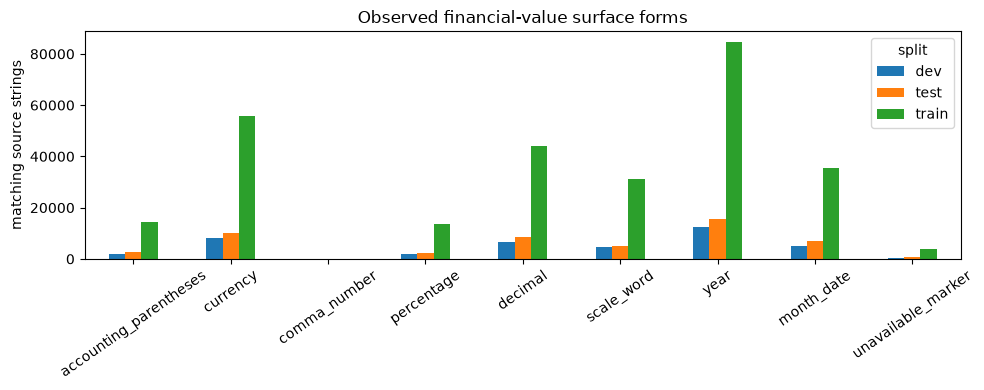

In [2]:
PATTERNS = {
    "accounting_parentheses": re.compile(r"\(\s*[$€£]?\s*\d[\d,]*(?:\.\d+)?%?\s*\)"),
    "currency": re.compile(r"[$€£]\s*\d"),
    "comma_number": re.compile(r"(?<!\d)\d{1,3}(?:,\d{3})+(?:\.\d+)?"),
    "percentage": re.compile(r"(?<!\w)-?\d+(?:\.\d+)?%"),
    "decimal": re.compile(r"(?<![\d.])-?\d+\.\d+"),
    "scale_word": re.compile(r"\b(?:thousand|thousands|million|millions|billion|billions)\b", re.I),
    "year": re.compile(r"(?<!\d)(?:19|20)\d{2}(?!\d)"),
    "month_date": re.compile(
        r"\b(?:january|february|march|april|may|june|july|august|september|october|november|december)\b",
        re.I,
    ),
}
UNAVAILABLE = {"", "-", "—", "–", "n/a", "na", "none", "not available"}


def source_strings(record):
    for row_index, row in enumerate(record["table"]):
        for column_index, value in enumerate(row):
            yield "table", f"table[{row_index}][{column_index}]", str(value)
    for index, value in enumerate(record["pre_text"] + record["post_text"]):
        yield "text", f"text[{index}]", str(value)


format_rows = []
examples = defaultdict(list)
for split_name, records in splits.items():
    for record in records:
        for location, pointer, value in source_strings(record):
            normalized = value.strip().lower()
            flags = {name: bool(pattern.search(value)) for name, pattern in PATTERNS.items()}
            flags["unavailable_marker"] = normalized in UNAVAILABLE
            for name, present in flags.items():
                if present and len(examples[name]) < 3:
                    examples[name].append(
                        {"split": split_name, "id": record["id"], "source": pointer, "raw": value}
                    )
            format_rows.append({"split": split_name, "location": location, **flags})

format_frame = pd.DataFrame(format_rows)
format_counts = (
    format_frame.drop(columns="location")
    .groupby("split")
    .sum()
    .T.assign(total=lambda frame: frame.sum(axis=1))
)
display(format_counts)
for name in format_counts.index:
    print(f"\n{name}:")
    display(pd.DataFrame(examples[name]))

ax = format_counts.drop(columns="total").plot.bar(figsize=(10, 4), rot=35)
ax.set_ylabel("matching source strings")
ax.set_title("Observed financial-value surface forms")
plt.tight_layout()

**Parsing decision.** Preserve every raw string. A later normalizer may emit a reversible candidate such as `{raw, numeric_token, sign_style, currency_symbol, percent, scale_word}` only when the token is locally recognizable. Parentheses, scale words, years, month names, and dashes are not sufficient on their own to establish a scalar value or its unit.

## 2. Reasoning-program grammar

The parser imported below is intentionally non-executing. Its failures mean only that a program lies outside its current narrow grammar; they are not claims that the dataset label is invalid.

In [3]:
CALL_NAME = re.compile(r"([a-z_]+)\(")
LITERAL = re.compile(r"(?<![\w.])-?(?:\d+\.?\d*|\.\d+)%?(?![\w.])")
INTERMEDIATE = re.compile(r"#\d+")
CONSTANT = re.compile(r"const_[A-Za-z0-9_]+")


def parser_failure_category(program, result):
    if result.is_valid:
        return "accepted by current grammar"
    if re.search(r"const_m\d+", program):
        return "signed named constant"
    if re.search(r"(?<!\d)\.\d+", program):
        return "leading-decimal literal"
    if "table_" in program and re.search(r"table_[a-z_]+\([^)]*[A-Za-z]", program):
        return "textual table argument"
    return "other syntax outside current grammar"


program_rows, failures = [], []
operation_counts = Counter()
for split_name, records in splits.items():
    for record in records:
        qa = record["qa"]
        program = qa["program"]
        result = parse_finqa_program(program)
        operations = CALL_NAME.findall(program)
        operation_counts.update(operations)
        row = {
            "split": split_name,
            "id": record["id"],
            "parse_status": "accepted" if result.is_valid else "outside current grammar",
            "failure_category": parser_failure_category(program, result),
            "operations": len(operations),
            "numeric_literals": len(LITERAL.findall(program)),
            "constants": len(CONSTANT.findall(program)),
            "intermediate_refs": len(INTERMEDIATE.findall(program)),
            "steps_field": len(qa["steps"]),
            "program_re_present": bool(qa["program_re"].strip()),
            "exe_ans_type": type(qa["exe_ans"]).__name__,
        }
        program_rows.append(row)
        if not result.is_valid and len(failures) < 8:
            failures.append({**row, "program": program, "parser_message": result.error})

program_frame = pd.DataFrame(program_rows)
display(program_frame.groupby(["split", "parse_status"]).size().unstack(fill_value=0))
display(
    program_frame.groupby("split")[
        ["operations", "numeric_literals", "constants", "intermediate_refs", "steps_field"]
    ].agg(["mean", "max"])
)
display(pd.DataFrame(operation_counts.most_common(), columns=["operation", "frequency"]).head(20))
display(
    program_frame[program_frame["parse_status"].ne("accepted")]
    .groupby("failure_category")
    .size()
    .rename("programs")
    .to_frame()
)
display(pd.DataFrame(failures)[["id", "failure_category", "program", "parser_message"]])

parse_status,accepted,outside current grammar
split,,
dev,840,43
test,1107,40
train,6029,222


operations     numeric_literals     constants     intermediate_refs      \
            mean max             mean max      mean max              mean max   
split                                                                           
dev     1.542469   5         2.738392  10  0.265006   4          0.546999   4   
test    1.544900   5         2.809939  10  0.213601   4          0.547515   4   
train   1.535434   6         2.812030  11  0.196769   4          0.536554   5   

      steps_field      
             mean max  
split                  
dev      1.542469   5  
test     1.544900   5  
train    1.535434   6

,operation,frequency
0,divide,5901
1,subtract,3676
2,add,1952
3,multiply,759
4,greater,154
5,table_average,129
6,table_max,66
7,table_sum,50
8,table_min,36
9,exp,9


,programs
failure_category,
leading-decimal literal,14
signed named constant,21
textual table argument,270


,id,failure_category,program,parser_message
0,ALLE/2016/page_29.pdf-1,textual table argument,"table_average(2016, none)","unsupported argument in: 'table_average(2016, ..."
1,WELL/2017/page_116.pdf-3,textual table argument,"table_average(beginning balance, none)",unsupported argument in: 'table_average(beginn...
2,RSG/2008/page_114.pdf-1,leading-decimal literal,"divide(285.7, .76)","unsupported argument in: 'divide(285.7, .76)'"
3,PNC/2009/page_31.pdf-4,leading-decimal literal,"subtract(.16, 1.94)","unsupported argument in: 'subtract(.16, 1.94)'"
4,AWK/2014/page_122.pdf-3,signed named constant,"multiply(3176, const_m1), divide(#0, 10379)","unsupported argument in: 'multiply(3176, const..."
5,AAPL/2008/page_77.pdf-1,textual table argument,table_max(cumulative foreign currency translat...,unsupported argument in: 'table_max(cumulative...
6,EOG/2017/page_78.pdf-1,textual table argument,"table_max(beginning balance, none)",unsupported argument in: 'table_max(beginning ...
7,TROW/2009/page_24.pdf-3,signed named constant,"multiply(16.5, const_m1), divide(#0, 22.1)","unsupported argument in: 'multiply(16.5, const..."


`program_re`, `steps`, and `exe_ans` are inspected as annotations here, never supplied to an answer-prediction input. The next parser increment should add tested support for observed forms (not execute programs) and compare parsed structure to `steps` only as an annotation-consistency diagnostic.

## 3. Evidence-to-source alignment

`text_n` is checked against the zero-based concatenation `pre_text + post_text`; `table_n` is checked against the zero-based raw table row. “Ambiguous” means a syntactically valid key whose supplied annotation text cannot be directly verified against the indexed raw text line. It is reported separately from an out-of-range key.

In [4]:
alignment_rows, alignment_examples = [], []
for split_name, records in splits.items():
    for record in records:
        context = record["pre_text"] + record["post_text"]
        for raw_key, annotation_text in record["qa"]["gold_inds"].items():
            checked = validate_evidence_key(
                raw_key, text_count=len(context), table_count=len(record["table"])
            )
            if not checked.is_valid:
                status, source_value = "invalid", None
            elif checked.source == "text":
                source_value = context[checked.index]
                status = "valid" if annotation_text == source_value else "ambiguous"
            else:
                source_value = record["table"][checked.index]
                status = "valid"
            row = {
                "split": split_name,
                "id": record["id"],
                "key": raw_key,
                "source": checked.source,
                "index": checked.index,
                "status": status,
                "reason": checked.reason,
            }
            alignment_rows.append(row)
            if len(alignment_examples) < 6 and (status != "valid" or len(alignment_examples) < 4):
                alignment_examples.append(
                    {**row, "annotation": annotation_text, "raw_source": source_value}
                )

alignment_frame = pd.DataFrame(alignment_rows)
display(
    alignment_frame.groupby(["split", "source", "status"]).size().rename("references").to_frame()
)
display(pd.DataFrame(alignment_examples))

anomaly = alignment_frame.query("status == 'invalid'")
display(anomaly)
assert anomaly[["id", "key"]].to_dict("records") == [
    {"id": "RE/2010/page_120.pdf-2", "key": "text_-1"}
]

references
split source status             
dev   table  valid          1071
      text   valid           442
test  table  valid          1318
      text   valid           585
train table  valid          7512
      text   invalid           1
             valid          3179

,split,id,key,source,index,status,reason,annotation,raw_source
0,train,ADI/2009/page_49.pdf-1,text_1,text,1,valid,NaN,"if libor changes by 100 basis points , our ann...","if libor changes by 100 basis points , our ann..."
1,train,ABMD/2012/page_75.pdf-1,table_2,table,2,valid,NaN,the granted of number of shares ( in thousands...,"[granted, 607, 18.13]"
2,train,ABMD/2012/page_75.pdf-1,text_15,text,15,valid,NaN,"during the year ended march 31 , 2012 , the co...","during the year ended march 31 , 2012 , the co..."
3,train,AAL/2018/page_13.pdf-2,table_1,table,1,valid,NaN,year the 2018 of gallons is 4447 ; the 2018 of...,"[2018, 4447, $ 2.23, $ 9896, 23.6% ( 23.6 % )]"
4,train,RE/2010/page_120.pdf-2,text_-1,text,-1,invalid,index outside source bounds,this guidance had no impact on how the company...,None


,split,id,key,source,index,status,reason
9597,train,RE/2010/page_120.pdf-2,text_-1,text,-1,invalid,index outside source bounds


## 4. Input serialization and leakage checks

Two inference-safe representations are compared: a structured payload retaining raw segments, and a deterministic row serialization for future retrieval. The row format explicitly includes the original header and every raw cell. It is not the historical FinQA utility and makes no use of gold evidence or labels.

In [5]:
FORBIDDEN_INPUT_FIELDS = {
    "answer",
    "exe_ans",
    "program",
    "program_re",
    "gold_inds",
    "steps",
    "ann_table_rows",
    "ann_text_rows",
    "explanation",
}


def structured_input(record):
    return {
        "id": record["id"],
        "question": record["qa"]["question"],
        "table": record["table"],
        "pre_text": record["pre_text"],
        "post_text": record["post_text"],
    }


def table_to_retrieval_text(table):
    header = [str(cell) for cell in table[0]]
    rows = ["header | " + " | ".join(header)]
    for row_index, row in enumerate(table[1:], start=1):
        pairs = [f"{column}: {value}" for column, value in zip(header, row, strict=False)]
        rows.append(f"row_{row_index} | " + " | ".join(pairs))
    return "\n".join(rows)


def assert_inference_safe(payload):
    assert not (set(payload) & FORBIDDEN_INPUT_FIELDS)
    rendered = json.dumps(payload, ensure_ascii=False)
    assert "__FORBIDDEN_SENTINEL__" not in rendered


coverage = []
for split_name, records in splits.items():
    for record in records:
        payload = structured_input(record)
        assert_inference_safe(payload)
        serialized = table_to_retrieval_text(record["table"])
        nonempty_cells = [str(cell) for row in record["table"] for cell in row if str(cell)]
        coverage.append(
            {
                "split": split_name,
                "structured_exact": payload["table"] == record["table"],
                "table_cells_preserved": all(cell in serialized for cell in nonempty_cells),
                "headers_preserved": all(
                    str(cell) in serialized for cell in record["table"][0] if str(cell)
                ),
            }
        )

sentinel_record = json.loads(json.dumps(splits["train"][0]))
sentinel_record["qa"]["answer"] = "__FORBIDDEN_SENTINEL__"
assert_inference_safe(structured_input(sentinel_record))

coverage_frame = pd.DataFrame(coverage)
display(coverage_frame.groupby("split").mean())
sample = splits["train"][0]
print("Structured keys:", list(structured_input(sample)))
print("Serialized rows (first two):")
print("\n".join(table_to_retrieval_text(sample["table"]).splitlines()[:2]))

,structured_exact,table_cells_preserved,headers_preserved
split,,,
dev,1.0,1.0,1.0
test,1.0,1.0,1.0
train,1.0,1.0,1.0


Structured keys: ['id', 'question', 'table', 'pre_text', 'post_text']
Serialized rows (first two):
header |  | october 31 2009 | november 1 2008
row_1 | : fair value of forward exchange contracts asset ( liability ) | october 31 2009: $ 6427 | november 1 2008: $ -23158 ( 23158 )


In [6]:
artifact_rows = []
for split_name, records in splits.items():
    for record in records:
        qa = record["qa"]
        artifact_rows.append(
            {
                "split": split_name,
                "table_retrieved_items": len(record["table_retrieved"]),
                "text_retrieved_items": len(record["text_retrieved"]),
                "model_input_items": len(qa["model_input"]),
                "tfidftopn_items": len(qa["tfidftopn"]),
                "model_input_gold_key_overlap": len(
                    {item[0] for item in qa["model_input"]} & set(qa["gold_inds"])
                ),
                "tfidftopn_gold_key_overlap": len(set(qa["tfidftopn"]) & set(qa["gold_inds"])),
            }
        )
artifact_frame = pd.DataFrame(artifact_rows)
display(artifact_frame.groupby("split").agg(["mean", "max"]))
print("Artifact example (keys only; not used as model input):")
print({field: type(sample[field]).__name__ for field in ("table_retrieved", "text_retrieved")})
print({field: type(sample["qa"][field]).__name__ for field in ("model_input", "tfidftopn")})

# Limitation: a structural contract can prevent serializer access to annotation fields,
# but it cannot prove a naturally occurring answer string never appears in a financial report.
assert (
    coverage_frame[["structured_exact", "table_cells_preserved", "headers_preserved"]].all().all()
)

table_retrieved_items     text_retrieved_items     model_input_items  \
                       mean max                 mean max              mean   
split                                                                        
dev                2.781427   5             2.218573   5          2.989807   
test               2.659111   5             2.340889   5          2.987794   
train              2.658775   5             2.341225   5          3.047512   

          tfidftopn_items     model_input_gold_key_overlap      \
      max            mean max                         mean max   
split                                                            
dev     3        1.345413   2                     1.446206   3   
test    3        1.386225   2                     1.391456   3   
train   9        1.346825   2                     1.710446   9   

      tfidftopn_gold_key_overlap      
                            mean max  
split                                 
dev                          0.0   0  
test                         0.0   0  
train                        0.0   0

Artifact example (keys only; not used as model input):
{'table_retrieved': 'list', 'text_retrieved': 'list'}
{'model_input': 'list', 'tfidftopn': 'dict'}


## Preprocessing decision table and next implementation steps

| Observed issue | Supporting evidence from this run | Chosen policy | Remaining uncertainty |
| --- | --- | --- | --- |
| Mixed financial surface forms | Counts and raw examples above include currencies, percentages, parentheses, scale words, dates, and unavailable markers. | Preserve raw strings and attach reversible parse candidates only with local context. | A surface match does not establish units or accounting semantics. |
| Program syntax exceeds the current parser | Accepted/outside-current-grammar counts and examples above. | Extend grammar only through observed, tested syntax; never use `eval`. | Parsing is not execution or label validation. |
| One out-of-range evidence key | `text_-1` remains the sole invalid positional key in the executed audit. | Preserve and flag raw annotation; do not repair it. | Its apparent source sentence does not justify rewriting the index. |
| Table-to-text representation can leak labels | Official repository historical update and the local structural checks. | Build serialization only from raw table/text/question; test forbidden-field exclusion. | Structural tests cannot identify all semantic/provenance leakage in external artifacts. |
| Existing retrieval/model artifacts | Artifact sizes and gold-key overlaps are measured above, but provenance is not established by the public record alone. | Exclude `table_retrieved`, `text_retrieved`, `model_input`, and `tfidftopn` from new inference inputs until separately verified. | Reproduction of the original pipeline may require a documented artifact-provenance study. |

Next: implement a small, tested normalizer that returns candidates without overwriting raw values; expand the non-executing program parser with observed grammar tests; and define a train-only baseline input contract using the two safe representations above.